In [1]:
from google.colab import drive
import os

drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/recommendation-pipeline"

assert os.path.isdir(PROJECT_DIR), "Project directory not found"

print("Project directory verified!")
print(PROJECT_DIR)

Mounted at /content/drive
Project directory verified!
/content/drive/MyDrive/recommendation-pipeline


In [2]:
import sys
import subprocess
import os

AIRFLOW_VERSION = "3.4.0"
PYTHON_VERSION = f"{sys.version_info.major}.{sys.version_info.minor}"

# Keep Airflow's runtime files separate from Google Drive.
os.environ["AIRFLOW_HOME"] = "/content/airflow"

constraints = (
    f"https://raw.githubusercontent.com/apache/airflow/"
    f"constraints-{AIRFLOW_VERSION}/"
    f"constraints-{PYTHON_VERSION}.txt"
)

print("Python version:", PYTHON_VERSION)
print("Installing Apache Airflow:", AIRFLOW_VERSION)

subprocess.run(
    [
        sys.executable, "-m", "pip", "install",
        f"apache-airflow=={AIRFLOW_VERSION}",
        "--constraint", constraints,
        "-q"
    ],
    check=True
)

subprocess.run(
    ["airflow", "version"],
    check=True
)

print("Apache Airflow installation successful!")

Python version: 3.13
Installing Apache Airflow: 3.4.0
Apache Airflow installation successful!


In [3]:
from pathlib import Path
import ast

dag_dir = Path(PROJECT_DIR) / "dags"
dag_dir.mkdir(parents=True, exist_ok=True)

dag_file = dag_dir / "movielens_pipeline_dag.py"

dag_code = '''
from datetime import datetime, timedelta
from pathlib import Path
import subprocess
import sys

from airflow.sdk import DAG, task

PROJECT_DIR = Path("/content/drive/MyDrive/recommendation-pipeline")

with DAG(
    dag_id="movielens_recommendation_pipeline",
    start_date=datetime(2026, 1, 1),
    schedule=None,
    catchup=False,
    tags=["dmml", "movielens", "recommendation"],
    default_args={"retries": 0},
) as dag:

    @task
    def check_project_files():
        required = [
            PROJECT_DIR / "pipeline_execution.py",
            PROJECT_DIR / "configs/config.yaml",
            PROJECT_DIR / "data/raw/ratings.csv",
        ]
        for path in required:
            if not path.exists():
                raise FileNotFoundError(str(path))
        print("Project files verified")

    @task
    def run_recommendation_pipeline():
        subprocess.run(
            [sys.executable, str(PROJECT_DIR / "pipeline_execution.py")],
            cwd=str(PROJECT_DIR),
            check=True,
        )
        print("Recommendation pipeline completed")

    @task
    def verify_pipeline_outputs():
        required = [
            PROJECT_DIR / "pipeline_runs/automated_full_run/models/popularity_model.pkl",
            PROJECT_DIR / "pipeline_runs/automated_full_run/models/svd_model.pkl",
            PROJECT_DIR / "pipeline_runs/automated_full_run/reports/model_evaluation_results.csv",
        ]
        for path in required:
            if not path.exists():
                raise FileNotFoundError(str(path))
        print("Model and evaluation artifacts verified")

    check_project_files() >> run_recommendation_pipeline() >> verify_pipeline_outputs()
'''

ast.parse(dag_code)
dag_file.write_text(dag_code)

print("Airflow DAG created successfully!")
print("DAG file:", dag_file)
print("DAG syntax verified!")

Airflow DAG created successfully!
DAG file: /content/drive/MyDrive/recommendation-pipeline/dags/movielens_pipeline_dag.py
DAG syntax verified!


In [4]:
import ast

dag_file = Path(PROJECT_DIR) / "dags/movielens_pipeline_dag.py"

ast.parse(dag_file.read_text())

print("DAG file exists:", dag_file.exists())
print("DAG name: movielens_recommendation_pipeline")
print("Tasks defined: 3")
print("Python syntax: VALID")

DAG file exists: True
DAG name: movielens_recommendation_pipeline
Tasks defined: 3
Python syntax: VALID


In [5]:
import os
import subprocess
import time
from pathlib import Path

os.environ["AIRFLOW_HOME"] = "/content/airflow"
os.environ["AIRFLOW__CORE__DAGS_FOLDER"] = str(
    Path(PROJECT_DIR) / "dags"
)

log_path = Path("/content/airflow_standalone.log")

log_file = open(log_path, "w")

airflow_process = subprocess.Popen(
    ["airflow", "standalone"],
    stdout=log_file,
    stderr=subprocess.STDOUT,
    env=os.environ.copy(),
    start_new_session=True
)

log_file.close()

print("Airflow startup initiated.")
print("Process ID:", airflow_process.pid)
print("Log file:", log_path)

time.sleep(20)

if airflow_process.poll() is None:
    print("Airflow process is running.")
else:
    print("Airflow process exited. Inspect the log below.")

print("\nRecent Airflow logs:")
print(log_path.read_text(errors="replace")[-3000:])

Airflow startup initiated.
Process ID: 8676
Log file: /content/airflow_standalone.log
Airflow process is running.

Recent Airflow logs:
standalone | Starting Airflow Standalone
standalone | Checking for new Dag files every 5 seconds (set [dag_processor] refresh_interval to change this)
2026-11-14T05:38:15.585108Z [warning  ] SimpleAuthManager is active but the deployment shape looks like production (non-sqlite backend, non-local API host, or a distributed executor). SimpleAuthManager stores passwords in plaintext at /content/airflow/simple_auth_manager_passwords.json.generated and prints generated passwords to stdout/logs on first init. Use a real auth manager (e.g. FAB or Keycloak) for production deployments. [airflow.api_fastapi.auth.managers.simple.simple_auth_manager] loc=simple_auth_manager.py:179
Simple auth manager | Password for user 'admin': xHufXGfumKP7dAA2
standalone | Checking database is initialized
2026-11-14T05:38:15.902493Z [info     ] Creating Airflow database tables f

In [6]:
import subprocess
import os

result = subprocess.run(
    ["airflow", "dags", "list"],
    capture_output=True,
    text=True,
    env=os.environ.copy()
)

print("Exit code:", result.returncode)
print(result.stdout[-5000:])

if result.returncode != 0:
    print("\nErrors:")
    print(result.stderr[-3000:])

Exit code: 0
                               | /usr/local/lib/python3.13/dist-packages/airflow/exampl | airflow | True      | example_dags                                   | None          
                                                        | e_dags/example_task_loops.py                           |         |           |                                                |               
movielens_recommendation_pipeline                       | /content/drive/MyDrive/recommendation-pipeline/dags/mo | airflow | True      | dags-folder                                    | None          
                                                        | vielens_pipeline_dag.py                                |         |           |                                                |               
partial_override_loop                                   | /usr/local/lib/python3.13/dist-packages/airflow/exampl | airflow | True      | example_dags                                   | None          
       

In [12]:
import sys
import subprocess
import importlib.util

print("Current Python:", sys.executable)

if importlib.util.find_spec("surprise") is None:
    print("Surprise is missing. Installing scikit-surprise...")

    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "scikit-surprise"
        ],
        check=True
    )
else:
    print("Surprise is already installed.")

# Verify in a fresh Python process
subprocess.run(
    [
        sys.executable,
        "-c",
        "import surprise; print('Surprise import successful!')"
    ],
    check=True
)

print("Step - dependency verification completed!")

Current Python: /usr/bin/python3
Surprise is already installed.
Step - dependency verification completed!


In [14]:
import sys
import subprocess

print("Current Python:", sys.executable)

# Install MLflow in the same Python environment used by Airflow
subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "mlflow",
        "-q"
    ],
    check=True
)

# Verify installation in a fresh Python process
subprocess.run(
    [
        sys.executable,
        "-c",
        "import mlflow; print('MLflow import successful!')"
    ],
    check=True
)

print("\n completed successfully!")

Current Python: /usr/bin/python3

 completed successfully!


In [17]:
import sys
import subprocess

print("Current Python:", sys.executable)

# Install Pandera with pandas support
subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "pandera[pandas]",
        "-q"
    ],
    check=True
)

# Verify all three required packages in a fresh process
subprocess.run(
    [
        sys.executable,
        "-c",
        """
import surprise
import mlflow
import pandera.pandas as pa

print("Surprise: OK")
print("MLflow: OK")
print("Pandera: OK")
"""
    ],
    check=True
)

print("\n completed successfully!")

Current Python: /usr/bin/python3

 completed successfully!


In [18]:
import subprocess
import os

result = subprocess.run(
    [
        "airflow",
        "dags",
        "test",
        "movielens_recommendation_pipeline"
    ],
    capture_output=True,
    text=True,
    env=os.environ.copy()
)

print("Exit code:", result.returncode)

print("\n===== DAG EXECUTION OUTPUT =====")
print(result.stdout[-5000:])

print("\n===== ERRORS / LOGS =====")
print(result.stderr[-5000:])

if result.returncode == 0:
    print("\nAIRFLOW DAG EXECUTION SUCCESSFUL!")
else:
    print("\nDAG execution failed. Review the error logs above.")

Exit code: 0

===== DAG EXECUTION OUTPUT =====
evious state of the Task instance: TaskInstanceState.QUEUED
Current task name:run_recommendation_pipeline
Dag name:movielens_recommendation_pipeline
2026-11-14T05:55:56.888663Z [info     ] ::endgroup::                   [task] loc=task_runner.py:2400

PIPELINE SUMMARY
train_rows: 80668
test_rows: 20168
user_features: 522
item_features: 7867
interaction_features: 80668
svd_rmse: 1.0145
svd_mae: 0.7827

MLflow tracking completed!
MLflow Run ID: ed9b2bc54cbd4b219e955b66160fbdbe
Recommendation pipeline completed
2026-11-14T05:56:12.732889Z [info     ] Done. Returned value was: None [airflow.task.operators.airflow.providers.standard.decorators.python._PythonDecoratedOperator] loc=python.py:233
2026-11-14T05:56:12.733267Z [info     ] ::group::Post Execute          [task] loc=task_runner.py:1674
2026-11-14T05:56:12.758364Z [info     ] Task instance state updated    [airflow.api_fastapi.execution_api.routes.task_instances] correlation_id=01a1d8a0-

In [19]:
from pathlib import Path
import json
from datetime import datetime, timezone

reports_dir = Path(PROJECT_DIR) / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

evidence = {
    "dag_id": "movielens_recommendation_pipeline",
    "execution_mode": "dry_run",
    "status": "success",
    "exit_code": 0,
    "tasks": [
        "check_project_files",
        "run_recommendation_pipeline",
        "verify_pipeline_outputs"
    ],
    "successful_tasks": 3,
    "run_duration_seconds": 29.906351,
    "mlflow_run_id": "ed9b2bc54cbd4b219e955b66160fbdbe",
    "dag_run_id": "manual__2026-11-14T05:55:43.658022+00:00"
}

output_file = reports_dir / "airflow_execution_evidence.json"

output_file.write_text(
    json.dumps(evidence, indent=4)
)

print("Airflow execution evidence saved!")
print("File:", output_file)
print("DAG status:", evidence["status"])
print("Successful tasks:", evidence["successful_tasks"])

Airflow execution evidence saved!
File: /content/drive/MyDrive/recommendation-pipeline/reports/airflow_execution_evidence.json
DAG status: success
Successful tasks: 3


## Step 7: Pipeline Architecture Diagram

This section generates the architecture diagram for the MovieLens
recommendation pipeline using Graphviz.

The diagram illustrates data ingestion, validation, preparation,
transformation, feature management, model training, evaluation,
MLflow tracking, and Apache Airflow orchestration.

Generated files:
- reports/pipeline_architecture.png
- reports/pipeline_architecture.pdf

Architecture diagram saved successfully!
PNG: /content/drive/MyDrive/recommendation-pipeline/reports/pipeline_architecture.png
PDF: /content/drive/MyDrive/recommendation-pipeline/reports/pipeline_architecture.pdf


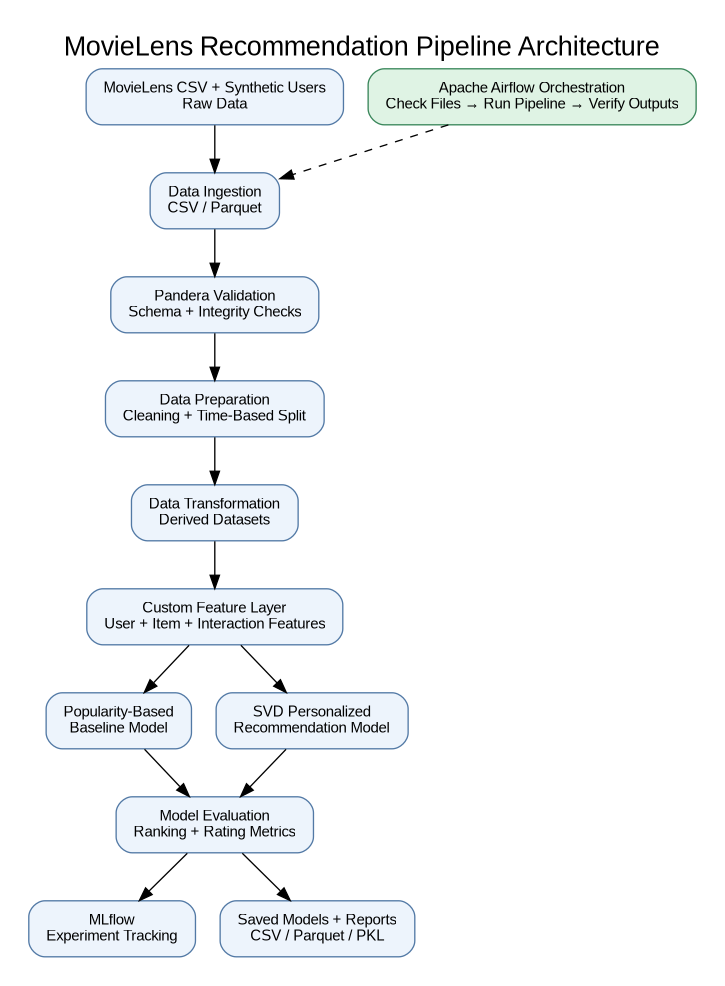

In [24]:
from pathlib import Path
import subprocess
import sys

# Install Graphviz Python package if needed
subprocess.run(
    [sys.executable, "-m", "pip", "install", "graphviz", "-q"],
    check=True
)

from graphviz import Digraph

project_dir = Path("/content/drive/MyDrive/recommendation-pipeline")
reports_dir = project_dir / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

dot = Digraph("MovieLens_Architecture")
dot.attr(
    rankdir="TB",
    bgcolor="white",
    label="MovieLens Recommendation Pipeline Architecture",
    labelloc="t",
    fontsize="20",
    fontname="Arial",
    pad="0.3"
)

dot.attr(
    "node",
    shape="box",
    style="rounded,filled",
    fillcolor="#EDF4FC",
    color="#5279A5",
    fontname="Arial",
    fontsize="11",
    margin="0.18,0.12"
)

dot.node("data", "MovieLens CSV + Synthetic Users\nRaw Data")
dot.node("ingest", "Data Ingestion\nCSV / Parquet")
dot.node("validate", "Pandera Validation\nSchema + Integrity Checks")
dot.node("prepare", "Data Preparation\nCleaning + Time-Based Split")
dot.node("transform", "Data Transformation\nDerived Datasets")
dot.node("features", "Custom Feature Layer\nUser + Item + Interaction Features")
dot.node("pop", "Popularity-Based\nBaseline Model")
dot.node("svd", "SVD Personalized\nRecommendation Model")
dot.node("eval", "Model Evaluation\nRanking + Rating Metrics")
dot.node("mlflow", "MLflow\nExperiment Tracking")
dot.node("artifacts", "Saved Models + Reports\nCSV / Parquet / PKL")

dot.edge("data", "ingest")
dot.edge("ingest", "validate")
dot.edge("validate", "prepare")
dot.edge("prepare", "transform")
dot.edge("transform", "features")
dot.edge("features", "pop")
dot.edge("features", "svd")
dot.edge("pop", "eval")
dot.edge("svd", "eval")
dot.edge("eval", "mlflow")
dot.edge("eval", "artifacts")

dot.node(
    "airflow",
    "Apache Airflow Orchestration\n"
    "Check Files → Run Pipeline → Verify Outputs",
    fillcolor="#DFF3E4",
    color="#39865A"
)
dot.edge("airflow", "ingest", style="dashed", constraint="false")

# Save PNG and PDF
png_file = dot.render(
    filename="pipeline_architecture",
    directory=str(reports_dir),
    format="png",
    cleanup=True
)

pdf_file = dot.render(
    filename="pipeline_architecture",
    directory=str(reports_dir),
    format="pdf",
    cleanup=True
)

print("Architecture diagram saved successfully!")
print("PNG:", png_file)
print("PDF:", pdf_file)

from IPython.display import Image, display
display(Image(filename=png_file))

## Feature Catalog and Documentation

### Objective
Document the features generated by the custom feature management layer of the MovieLens recommendation pipeline.

### Feature Categories
1. **User Features:** Describe user preferences and rating activity.
2. **Item Features:** Describe movie popularity, ratings, and related characteristics.
3. **Interaction Features:** Describe relationships between users and movies.

### Deliverables
Generate a feature catalog containing feature names, data types, descriptions, and their intended purpose.

The catalog will be saved in the 'reports/' directory and included in the final GitHub submission.

This step documents existing features and does not regenerate features or retrain models.

In [25]:
from pathlib import Path
import pandas as pd

project_dir = Path("/content/drive/MyDrive/recommendation-pipeline")

feature_dirs = [
    project_dir / "data/features",
    project_dir / "pipeline_runs/automated_full_run/data/features",
]

print("===== AVAILABLE FEATURE FILES =====")

for folder in feature_dirs:
    print(f"\nFolder: {folder}")

    if not folder.exists():
        print("Folder not found")
        continue

    files = sorted(
        list(folder.glob("*.parquet")) +
        list(folder.glob("*.csv"))
    )

    if not files:
        print("No CSV or Parquet files found")
        continue

    for file in files:
        try:
            if file.suffix == ".parquet":
                df = pd.read_parquet(file)
            else:
                df = pd.read_csv(file)

            print(f"\nFile: {file.name}")
            print(f"Rows: {len(df)}")
            print("Columns and data types:")

            for column, dtype in df.dtypes.items():
                print(f"  {column}: {dtype}")

        except Exception as e:
            print(f"Could not inspect {file.name}: {e}")

===== AVAILABLE FEATURE FILES =====

Folder: /content/drive/MyDrive/recommendation-pipeline/data/features

File: interaction_features.csv
Rows: 80668
Columns and data types:
  userId: int64
  movieId: int64
  rating: float64
  timestamp: int64
  year: int64
  month: int64
  day: int64

File: interaction_features.parquet
Rows: 80668
Columns and data types:
  userId: int64
  movieId: int64
  rating: float64
  timestamp: int64
  year: int32
  month: int32
  day: int32

File: item_features.csv
Rows: 7867
Columns and data types:
  movieId: int64
  item_avg_rating: float64
  item_popularity: int64
  unique_user_count: int64

File: item_features.parquet
Rows: 7867
Columns and data types:
  movieId: int64
  item_avg_rating: float64
  item_popularity: int64
  unique_user_count: int64

File: user_features.csv
Rows: 522
Columns and data types:
  userId: int64
  user_avg_rating: float64
  user_activity_count: int64

File: user_features.parquet
Rows: 522
Columns and data types:
  userId: int64
  us

### Feature Catalog Generation

This step creates a structured catalog of the existing user, item, and interaction features.

The catalog documents:
- Feature category and name
- Data type
- Feature description
- Intended purpose

**Feature datasets:**
- User features: 522 records
- Item features: 7,867 records
- Interaction features: 80,668 records

The catalog is generated from the existing feature datasets and saved as 'reports/feature_catalog.csv'.

No model retraining or feature regeneration is performed.

In [26]:
from pathlib import Path
import pandas as pd

project_dir = Path("/content/drive/MyDrive/recommendation-pipeline")
feature_dir = project_dir / "data/features"
reports_dir = project_dir / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

# Feature descriptions and purposes
feature_info = {
    "userId": (
        "Unique identifier for a user",
        "Identify users and join user-related datasets"
    ),
    "movieId": (
        "Unique identifier for a movie",
        "Identify movies and join item-related datasets"
    ),
    "user_avg_rating": (
        "Average rating given by a user",
        "Summarize user rating behavior"
    ),
    "user_activity_count": (
        "Number of ratings submitted by a user",
        "Measure user engagement"
    ),
    "item_avg_rating": (
        "Average rating received by a movie",
        "Summarize movie rating performance"
    ),
    "item_popularity": (
        "Number of ratings received by a movie",
        "Measure movie popularity"
    ),
    "unique_user_count": (
        "Number of distinct users who rated a movie",
        "Measure the breadth of movie engagement"
    ),
    "rating": (
        "Rating given by a user to a movie",
        "Represent explicit user-item feedback"
    ),
    "timestamp": (
        "Original interaction timestamp in Unix seconds",
        "Support chronological analysis and splitting"
    ),
    "year": (
        "Calendar year extracted from the interaction timestamp",
        "Support time-based analysis"
    ),
    "month": (
        "Calendar month extracted from the interaction timestamp",
        "Support monthly interaction analysis"
    ),
    "day": (
        "Day of the month extracted from the interaction timestamp",
        "Support daily interaction analysis"
    ),
}

feature_files = {
    "User": "user_features.parquet",
    "Item": "item_features.parquet",
    "Interaction": "interaction_features.parquet",
}

catalog_rows = []

for category, filename in feature_files.items():
    df = pd.read_parquet(feature_dir / filename)

    for column in df.columns:
        description, purpose = feature_info.get(
            column,
            ("Description pending", "Purpose pending")
        )

        catalog_rows.append({
            "Feature Category": category,
            "Feature Name": column,
            "Data Type": str(df[column].dtype),
            "Description": description,
            "Purpose": purpose
        })

catalog = pd.DataFrame(catalog_rows)

output_file = reports_dir / "feature_catalog.csv"
catalog.to_csv(output_file, index=False)

print("FEATURE CATALOG GENERATED SUCCESSFULLY!")
print("Total catalog entries:", len(catalog))
print("Saved to:", output_file)

display(catalog)

FEATURE CATALOG GENERATED SUCCESSFULLY!
Total catalog entries: 14
Saved to: /content/drive/MyDrive/recommendation-pipeline/reports/feature_catalog.csv


,Feature Category,Feature Name,Data Type,Description,Purpose
0,User,userId,int64,Unique identifier for a user,Identify users and join user-related datasets
1,User,user_avg_rating,float64,Average rating given by a user,Summarize user rating behavior
2,User,user_activity_count,int64,Number of ratings submitted by a user,Measure user engagement
3,Item,movieId,int64,Unique identifier for a movie,Identify movies and join item-related datasets
4,Item,item_avg_rating,float64,Average rating received by a movie,Summarize movie rating performance
5,Item,item_popularity,int64,Number of ratings received by a movie,Measure movie popularity
6,Item,unique_user_count,int64,Number of distinct users who rated a movie,Measure the breadth of movie engagement
7,Interaction,userId,int64,Unique identifier for a user,Identify users and join user-related datasets
8,Interaction,movieId,int64,Unique identifier for a movie,Identify movies and join item-related datasets
9,Interaction,rating,float64,Rating given by a user to a movie,Represent explicit user-item feedback


## Project Documentation and GitHub Preparation

### Objective
Prepare the MovieLens recommendation pipeline for reproducible execution and GitHub submission.

### Documentation Requirements
- Verify the project folder structure.
- Review the existing 'README.md'.
- Review the Python dependencies in 'requirements.txt'.
- Document the installation and execution steps.
- Include links to the architecture diagram, feature catalog, validation reports, and model evaluation results.
- Prepare the project for GitHub without uploading unnecessary temporary files, credentials, or large generated artifacts.

### Approach
The existing project files will be inspected before making changes. This avoids overwriting working code or duplicating documentation.



In [27]:
from pathlib import Path

project_dir = Path("/content/drive/MyDrive/recommendation-pipeline")

print("===== PROJECT ROOT FILES =====")

for item in sorted(project_dir.iterdir()):
    if item.is_dir():
        print(f"[DIR]  {item.name}/")
    else:
        print(f"[FILE] {item.name}")

print("\n===== README.md =====")

readme = project_dir / "README.md"

if readme.exists():
    print(readme.read_text(encoding="utf-8")[:12000])
else:
    print("README.md not found")

print("\n===== requirements.txt =====")

requirements = project_dir / "requirements.txt"

if requirements.exists():
    print(requirements.read_text(encoding="utf-8"))
else:
    print("requirements.txt not found")

print("\n===== REPORTS FOLDER =====")

reports_dir = project_dir / "reports"

if reports_dir.exists():
    for item in sorted(reports_dir.iterdir()):
        if item.is_file():
            print(item.name)

===== PROJECT ROOT FILES =====
[FILE] README.md
[DIR]  configs/
[DIR]  dags/
[DIR]  data/
[DIR]  mlartifacts/
[FILE] mlflow.db
[DIR]  models/
[DIR]  notebooks/
[FILE] pipeline_execution.py
[FILE] pipeline_execution.py.backup
[FILE] pipeline_execution.py.before_full_run
[FILE] pipeline_execution.py.before_mlflow
[FILE] pipeline_execution.py.before_step5q
[FILE] pipeline_execution.py.before_step5t
[FILE] pipeline_execution.py.before_step5u
[FILE] pipeline_execution.py.before_step5v
[DIR]  pipeline_runs/
[DIR]  reports/
[FILE] requirements.txt
[FILE] run_pipeline.py
[DIR]  src/

===== README.md =====

# End-to-End Data Management Pipeline for a Recommendation System

## 1. Project Overview

This project implements an end-to-end data management pipeline
for a movie recommendation system using the MovieLens Latest
Small dataset.

The pipeline covers data ingestion, data validation, data
preparation, transformation, feature management, model training,
evaluation, and workflow orchestration.


### Update Assignment README

The README documents the completed MovieLens recommendation pipeline.

It includes:
- Project objectives and architecture
- Dataset information and processing stages
- Feature management and recommendation models
- Evaluation results and MLflow tracking
- Full-run and dry-run execution commands
- Apache Airflow orchestration
- Reproducibility requirements and limitations

The existing README will be backed up before modification.

In [30]:
from pathlib import Path
import shutil

# ============================================================
# STEP 9.3B - UPDATE PROJECT README
# ============================================================

project_dir = Path("/content/drive/MyDrive/recommendation-pipeline")
readme_path = project_dir / "README.md"
backup_path = project_dir / "README.md.before_step9"

# Step 1: Back up the original README
if readme_path.exists() and not backup_path.exists():
    shutil.copy2(readme_path, backup_path)
    print("Original README backed up successfully.")

# Step 2: Prepare the updated README content
readme_content = r'''# End-to-End Data Management Pipeline for a Recommendation System

## 1. Project Overview

This project implements end-to-end data management pipeline
for a movie recommendation system using the MovieLens Latest
Small dataset.

The project was developed for Data Management for Machine
Learning (DMML) Assignment 2.

The pipeline covers:

1. Data ingestion
2. Data validation
3. Data preparation
4. Data transformation
5. Feature management
6. Model training
7. Model evaluation
8. MLflow experiment tracking
9. Apache Airflow orchestration

## 2. Dataset Description

**Dataset:** MovieLens Latest Small

**Source:** https://grouplens.org/datasets/movielens/latest/

Original dataset files:

- movies.csv
- ratings.csv
- tags.csv
- links.csv

A synthetic users.csv dataset was also generated.

Dataset statistics:

| Dataset | Records |
|---|---:|
| Movies | 9,742 |
| Ratings | 100,836 |
| Tags | 3,683 |
| Synthetic Users | 610 |

The data is stored in CSV and Parquet formats.

## 3. Technology Stack

| Component | Technology |
|---|---|
| Programming Language | Python |
| Development Environment | Google Colab |
| Data Processing | Pandas, NumPy |
| Data Validation | Pandera |
| Storage | CSV, Parquet |
| Feature Management | Custom Feature Store |
| Recommendation Models | Popularity-Based, SVD |
| Model Library | Surprise |
| Experiment Tracking | MLflow |
| Orchestration | Apache Airflow |
| Evaluation | Custom Metrics, Scikit-learn |
| Architecture Diagram | Graphviz |

## 4. Project Architecture

The pipeline follows these stages:

Data Ingestion
-> Data Validation
-> Data Preparation
-> Data Transformation
-> Feature Management
-> Model Training
-> Model Evaluation

MLflow tracks experiments and Apache Airflow orchestrates
pipeline execution.

The architecture diagram is available below:

![Pipeline Architecture](reports/pipeline_architecture.png)

A PDF version is also available at:

reports/pipeline_architecture.pdf

## 5. Data Ingestion

The pipeline ingests MovieLens CSV datasets and synthetic
user information.

The datasets are stored in:

- data/raw/
- data/processed/

Processed datasets are also saved in Parquet format.

## 6. Data Validation

Pandera is used for schema validation.

Validation checks include:

- Missing values
- Duplicate records
- Data types
- Rating constraints
- Referential integrity
- Dataset consistency

Validation and integrity reports are saved in reports/.

## 7. Data Preparation

The ratings dataset is divided using a chronological
80/20 train-test split.

| Dataset | Records |
|---|---:|
| Training interactions | 80,668 |
| Testing interactions | 20,168 |

This approach supports time-based recommendation evaluation.

## 8. Data Transformation

The pipeline prepares derived datasets for downstream
feature managemnt, training and evaluation.

The transformation logic is implemented in src/transformation/.

## 9. Feature Management

A custom feature management layer generates reusable
user, item, and interaction features.

| Feature Dataset | Records |
|---|---:|
| User Features | 522 |
| Item Features | 7,867 |
| Interaction Features | 80,668 |

Feature datasets are saved in:

data/features/

The feature catalog contains 14 entries and is available at:

reports/feature_catalog.csv

## 10. Recommendation Models

### 10.1 Popularity-Based Model

The popularity model provides a non-personalized
recommendation baseline using historical movie popularity.

### 10.2 SVD Model

The SVD model uses collaborative filtering through
the Surprise library to generate personalized predictions.

Both models are trained using the training interactions.

## 11. Model Evaluation

The evaluation framework includes:

- Precision@10
- Recall@10
- NDCG@10
- Coverage
- Diversity
- RMSE
- MAE

The models are compared using saved evaluation results.

Evaluation report:

reports/model_evaluation_results.csv

## 12. Experiment Tracking

MLflow is used to track:

- Experiment runs
- Model parameters
- Evaluation metrics
- Model artifacts
- Pipeline execution details

The local execution environment uses SQLite-backed
MLflow tracking.

Runtime MLflow databases and artifacts are not intended
to be committed to GitHub.

## 13. Pipeline Execution

The main pipeline entry point is:

pipeline_execution.py

### 13.1 Full Pipeline Execution

Run the complete pipeline, including model training:

    python pipeline_execution.py --full-run

This generates trained models and evaluation outputs.

### 13.2 Dry-Run Execution

Run the pipeline using existing saved models:

    python pipeline_execution.py

Dry-run mode does not retrain models or overwrite
existing trained model artifacts.

A successful full run is required before the dry run
can reuse saved models.

## 14. Apache Airflow Orchestration

The orchestration DAG is located at:

dags/movielens_pipeline_dag.py

The DAG contains three dependent tasks:

1. check_project_files
2. run_recommendation_pipeline
3. verify_pipeline_outputs

The Airflow DAG executes the pipeline in dry-run mode.

The DAG was tested successfully using:

    airflow dags test movielens_recommendation_pipeline

All three tasks completed successfully.

Execution evidence:

reports/airflow_execution_evidence.json

The successful DAG execution was also documented
with screenshots captured in Google Colab.

## 15. Installation Instructions

The project was developed in Google Colab.

Clone the repository:

    git clone <your-repository-url>

Navigate to the project directory:

    cd recommendation-pipeline

Install core dependencies:

    pip install -r requirements.txt

Apache Airflow must be installed separately using
the appropriate version-specific constraints file.

The implementation was tested with Apache Airflow 3.4.0
in Google Colab.

For Airflow 3.4.0 with Python 3.13, an example is:

    pip install "apache-airflow==3.4.0" --constraint "https://raw.githubusercontent.com/apache/airflow/constraints-3.4.0/constraints-3.13.txt"

The MovieLens CSV datasets must be placed in data/raw/.

The Airflow DAG currently uses a Google Colab-specific
project path. Update PROJECT_DIR when running elsewhere.

Google Drive must be mounted when using the original
Colab project directory.

## 16. Project Structure

    recommendation-pipeline/
    |
    |-- configs/
    |-- dags/
    |-- data/
    |   |-- raw/
    |   |-- processed/
    |   |-- features/
    |   |-- errors/
    |-- models/
    |-- notebooks/
    |-- pipeline_runs/
    |-- reports/
    |-- src/
    |   |-- ingestion/
    |   |-- validation/
    |   |-- preparation/
    |   |-- transformation/
    |   |-- features/
    |   |-- training/
    |   |-- evaluation/
    |-- pipeline_execution.py
    |-- run_pipeline.py
    |-- requirements.txt
    |-- README.md

## 17. Important Deliverables

The repository includes or documents:

- Modular pipeline source code
- Configuration files
- Data validation reports
- Feature catalog
- Model evaluation results
- MLflow experiment tracking
- Airflow DAG
- Successful orchestration execution evidence
- Architecture diagram
- Google Colab notebooks

## 18. Limitations

- The project uses the MovieLens Latest Small dataset.
- User demographic information is synthetic.
- The popularity baseline does not personalize recommendations.
- SVD depends on historical user-item interactions.
- Google Colab runtimes are temporary.
- The Airflow DAG uses a dry-run wrapper around the pipeline.
- Existing trained models are required for dry-run evaluation.
- The current DAG contains environment-specific paths.

## 19. Future Improvements

Potential enhancements include:

- Support for larger datasets
- Richer user and movie features
- Hybrid recommendation models
- Improved coverage and diversity
- Implement automated monitoring and alerts for pipeline failures, data quality issues, and model performance degradation.

## 20. Assignment

Data Management for Machine Learning (DMML)

Assignment 2:

End-to-End Data Management Pipeline for a Recommendation System.
'''

# Step 3: Save the updated README
readme_path.write_text(readme_content, encoding="utf-8")

# Step 4: Verify the saved file
saved_content = readme_path.read_text(encoding="utf-8")

print("\n===== STEP 9.3B RESULT =====")
print("README updated successfully!")
print("File:", readme_path)
print("Backup:", backup_path)
print("README size:", len(saved_content), "characters")
print("Total lines:", len(saved_content.splitlines()))

print("\nFirst five lines of README:")
print("\n".join(saved_content.splitlines()[:5]))


===== STEP 9.3B RESULT =====
README updated successfully!
File: /content/drive/MyDrive/recommendation-pipeline/README.md
Backup: /content/drive/MyDrive/recommendation-pipeline/README.md.before_step9
README size: 7996 characters
Total lines: 360

First five lines of README:
# End-to-End Data Management Pipeline for a Recommendation System

## 1. Project Overview

This project implements end-to-end data management pipeline


### Dependency Verification

**Objective:** Verify that the project's `requirements.txt` contains the dependencies needed to reproduce the recommendation pipeline.

This step checks:
- Core data processing and validation libraries
- Recommendation model dependencies
- MLflow experiment tracking
- Apache Airflow orchestration
- Visualization and configuration libraries

The existing dependency file will be inspected before making changes.

In [31]:
from pathlib import Path
import importlib.metadata as metadata

project_dir = Path("/content/drive/MyDrive/recommendation-pipeline")
requirements_path = project_dir / "requirements.txt"

print("===== REQUIREMENTS.TXT =====")
print(requirements_path.read_text(encoding="utf-8"))

print("\n===== INSTALLED PACKAGE VERSIONS =====")

packages = [
    "pandas",
    "numpy",
    "pandera",
    "pyarrow",
    "scikit-learn",
    "scikit-surprise",
    "mlflow",
    "apache-airflow",
    "matplotlib",
    "seaborn",
    "PyYAML",
    "graphviz",
]

for package in packages:
    try:
        version = metadata.version(package)
        print(f"{package}: {version}")
    except metadata.PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")

print("\nDependency verification completed.")

===== REQUIREMENTS.TXT =====
pandas==2.2.3
numpy==2.4.6
pandera==0.36.0
pyarrow==23.0.1
scikit-learn==1.6.1
scikit-surprise==1.1.5
mlflow==3.18.0
matplotlib==3.10.0
seaborn==0.13.2
pyyaml==6.0.3


===== INSTALLED PACKAGE VERSIONS =====
pandas: 2.2.3
numpy: 2.4.6
pandera: 0.36.0
pyarrow: 23.0.1
scikit-learn: 1.6.1
scikit-surprise: 1.1.5
mlflow: 3.18.0
apache-airflow: 3.4.0
matplotlib: 3.10.0
seaborn: 0.13.2
PyYAML: 6.0.3
graphviz: 0.21

Dependency verification completed.


### Finalize Project Dependencies

The installed package versions were verified against the existing requirements file.

The core dependencies are retained at their tested versions. The Python Graphviz package is added to support reproducible architecture diagram generation.

Apache Airflow 3.4.0 is documented separately in the README because its installation requires Python-version-specific constraints.

In [32]:
from pathlib import Path
import shutil

project_dir = Path("/content/drive/MyDrive/recommendation-pipeline")
requirements_path = project_dir / "requirements.txt"
backup_path = project_dir / "requirements.txt.before_step9"

# Preserve the original file
if not backup_path.exists():
    shutil.copy2(requirements_path, backup_path)

# Read existing dependencies
lines = requirements_path.read_text(
    encoding="utf-8"
).splitlines()

# Add Graphviz only if it is not already listed
if not any(
    line.strip().lower().startswith("graphviz==")
    for line in lines
):
    lines.append("graphviz==0.21")

# Save the updated file
requirements_path.write_text(
    "\n".join(lines) + "\n",
    encoding="utf-8"
)

print("REQUIREMENTS UPDATED SUCCESSFULLY!")
print("\nFinal requirements.txt:\n")
print(requirements_path.read_text(encoding="utf-8"))
print("Backup:", backup_path)

REQUIREMENTS UPDATED SUCCESSFULLY!

Final requirements.txt:

pandas==2.2.3
numpy==2.4.6
pandera==0.36.0
pyarrow==23.0.1
scikit-learn==1.6.1
scikit-surprise==1.1.5
mlflow==3.18.0
matplotlib==3.10.0
seaborn==0.13.2
pyyaml==6.0.3
graphviz==0.21

Backup: /content/drive/MyDrive/recommendation-pipeline/requirements.txt.before_step9


### GitHub Repository Preparation

**Objective:** Prepare the project for GitHub submission by identifying source files, documentation, and generated artifacts.

A '.gitignore' file is created to prevent unnecessary files from being committed, including:
- Python cache and temporary files
- Backup copies of source files
- MLflow runtime databases and artifacts
- Large generated datasets and model files
- Local environment and credential files

The source code, notebooks, configuration, architecture diagram, feature catalog, validation reports, and model evaluation results will remain available for submission.

**Note:** Creating '.gitignore' does not delete any project files or modify trained models.

In [33]:
from pathlib import Path

project_dir = Path("/content/drive/MyDrive/recommendation-pipeline")
gitignore_path = project_dir / ".gitignore"

gitignore_content = """
# Python cache
__pycache__/
*.py[cod]
.ipynb_checkpoints/
.pytest_cache/

# Local environments
.venv/
venv/
.env
.env.*
!.env.example

# Credentials and secrets
*credentials*.json
*service-account*.json
*.pem
*.key

# Backup files
*.backup
*.before_*
*.bak

# MLflow runtime files
mlflow.db
mlflow.db-*
mlruns/
mlartifacts/

# Generated model artifacts
models/*.pkl
models/*.joblib
models/*.pickle
models/*.npz

# Generated pipeline runs
pipeline_runs/

# Generated datasets
data/raw/
data/processed/
data/features/
data/errors/

# Colab and temporary files
*.tmp
*.log
.DS_Store
Thumbs.db
"""

gitignore_path.write_text(
    gitignore_content.strip() + "\n",
    encoding="utf-8"
)

print("GITIGNORE CREATED SUCCESSFULLY!")
print("File:", gitignore_path)

print("\n===== GITIGNORE CONTENT =====")
print(gitignore_path.read_text(encoding="utf-8"))

GITIGNORE CREATED SUCCESSFULLY!
File: /content/drive/MyDrive/recommendation-pipeline/.gitignore

===== GITIGNORE CONTENT =====
# Python cache
__pycache__/
*.py[cod]
.ipynb_checkpoints/
.pytest_cache/

# Local environments
.venv/
venv/
.env
.env.*
!.env.example

# Credentials and secrets
*credentials*.json
*service-account*.json
*.pem
*.key

# Backup files
*.backup
*.before_*
*.bak

# MLflow runtime files
mlflow.db
mlflow.db-*
mlruns/
mlartifacts/

# Generated model artifacts
models/*.pkl
models/*.joblib
models/*.pickle
models/*.npz

# Generated pipeline runs
pipeline_runs/

# Generated datasets
data/raw/
data/processed/
data/features/
data/errors/

# Colab and temporary files
*.tmp
*.log
.DS_Store
Thumbs.db



### Final GitHub Readiness Verification

**Objective:** Verify that the repository contains the essential source code, configuration, documentation, and assignment deliverables.

The verification checks:
- Main pipeline execution script
- Apache Airflow DAG
- Project configuration
- README and dependencies
- Modular source code
- Development notebooks
- Architecture diagram
- Feature catalog
- Validation and model evaluation reports
- Orchestration execution evidence

In [35]:
from pathlib import Path

project_dir = Path("/content/drive/MyDrive/recommendation-pipeline")

required_files = {
    "README": "README.md",
    "Requirements": "requirements.txt",
    "Gitignore": ".gitignore",
    "Main Pipeline": "pipeline_execution.py",
    "Configuration": "configs/config.yaml",
    "Airflow DAG": "dags/movielens_pipeline_dag.py",
    "Architecture PNG": "reports/pipeline_architecture.png",
    "Architecture PDF": "reports/pipeline_architecture.pdf",
    "Feature Catalog": "reports/feature_catalog.csv",
    "Validation Report": "reports/validation_report.csv",
    "Integrity Report": "reports/integrity_report.csv",
    "Model Evaluation": "reports/model_evaluation_results.csv",
    "Airflow Evidence": "reports/airflow_execution_evidence.json",
}

required_dirs = {
    "Source Code": "src",
    "Notebooks": "notebooks",
    "Reports": "reports",
    "DAGs": "dags",
}

missing = []

print("===== REQUIRED FILES =====")

for label, relative_path in required_files.items():
    path = project_dir / relative_path
    status = "PASS" if path.is_file() else "MISSING"
    print(f"{status:8} | {label}: {relative_path}")

    if not path.is_file():
        missing.append(relative_path)

print("\n===== REQUIRED DIRECTORIES =====")

for label, relative_path in required_dirs.items():
    path = project_dir / relative_path
    status = "PASS" if path.is_dir() else "MISSING"
    print(f"{status:8} | {label}: {relative_path}")

    if not path.is_dir():
        missing.append(relative_path)

print("\n===== SOURCE MODULES =====")

python_files = sorted((project_dir / "src").rglob("*.py"))

print("Python source files:", len(python_files))

for path in python_files:
    print(" -", path.relative_to(project_dir))

print("\n===== NOTEBOOKS =====")

notebooks = sorted((project_dir / "notebooks").glob("*.ipynb"))

print("Notebook count:", len(notebooks))

for path in notebooks:
    print(" -", path.name)

print("\n===== FINAL VERIFICATION =====")

if not missing:
    print("ALL REQUIRED FILES AND DIRECTORIES FOUND!")
    print("Project structure is ready for GitHub review.")
else:
    print("Missing items:")
    for item in missing:
        print(" -", item)

===== REQUIRED FILES =====
PASS     | README: README.md
PASS     | Requirements: requirements.txt
PASS     | Gitignore: .gitignore
PASS     | Main Pipeline: pipeline_execution.py
PASS     | Configuration: configs/config.yaml
PASS     | Airflow DAG: dags/movielens_pipeline_dag.py
PASS     | Architecture PNG: reports/pipeline_architecture.png
PASS     | Architecture PDF: reports/pipeline_architecture.pdf
PASS     | Feature Catalog: reports/feature_catalog.csv
PASS     | Validation Report: reports/validation_report.csv
PASS     | Integrity Report: reports/integrity_report.csv
PASS     | Model Evaluation: reports/model_evaluation_results.csv
PASS     | Airflow Evidence: reports/airflow_execution_evidence.json

===== REQUIRED DIRECTORIES =====
PASS     | Source Code: src
PASS     | Notebooks: notebooks
PASS     | Reports: reports
PASS     | DAGs: dags

===== SOURCE MODULES =====
Python source files: 22
 - src/__init__.py
 - src/evaluation/__init__.py
 - src/evaluation/evaluate.py
 - src/eva

## Final Assignment Report

### Objective

Prepare a three-page PDF report summarizing the design, implementation, results and limitations of the MovieLens recommendation pipeline.

### Report Structure

**Page 1: Project Overview and Data Management**
- Dataset and technology stack
- Pipeline architecture
- Data ingestion and validation
- Train-test split

**Page 2: Feature Management and Model Evaluation**
- User, item, and interaction features
- Popularity-based and SVD models
- Model evaluation results
- MLflow experiment tracking

**Page 3: Orchestration and Conclusions**
- Apache Airflow DAG
- Successful workflow execution
- Limitations and future improvements
- Conclusion

### Source Files

The report will use the existing architecture diagram, validation reports, feature catalog, model evaluation results, and Airflow execution evidence stored in the 'reports/' directory.

In [36]:
from pathlib import Path
import pandas as pd
import json

project_dir = Path("/content/drive/MyDrive/recommendation-pipeline")
reports_dir = project_dir / "reports"

print("========== STEP 10.2: REPORT DATA VERIFICATION ==========")

# 1. Data validation
print("\n===== VALIDATION REPORT =====")
validation_path = reports_dir / "validation_report.csv"

if validation_path.exists():
    display(pd.read_csv(validation_path))
else:
    print("Validation report not found")

# 2. Referential integrity
print("\n===== INTEGRITY REPORT =====")
integrity_path = reports_dir / "integrity_report.csv"

if integrity_path.exists():
    display(pd.read_csv(integrity_path))
else:
    print("Integrity report not found")

# 3. Model evaluation
print("\n===== MODEL EVALUATION RESULTS =====")
evaluation_path = reports_dir / "model_evaluation_results.csv"

if evaluation_path.exists():
    display(pd.read_csv(evaluation_path))
else:
    print("Model evaluation report not found")

# 4. Feature catalog summary
print("\n===== FEATURE CATALOG SUMMARY =====")
catalog_path = reports_dir / "feature_catalog.csv"

if catalog_path.exists():
    catalog = pd.read_csv(catalog_path)

    print("Total catalog entries:", len(catalog))
    display(
        catalog.groupby("Feature Category")
        .size()
        .reset_index(name="Feature Count")
    )
else:
    print("Feature catalog not found")

# 5. Airflow execution evidence
print("\n===== AIRFLOW EXECUTION EVIDENCE =====")
airflow_path = reports_dir / "airflow_execution_evidence.json"

if airflow_path.exists():
    with open(airflow_path, "r", encoding="utf-8") as f:
        airflow_evidence = json.load(f)

    print(json.dumps(airflow_evidence, indent=2))
else:
    print("Airflow execution evidence not found")

# 6. Architecture diagram
print("\n===== ARCHITECTURE DIAGRAM =====")
architecture_path = reports_dir / "pipeline_architecture.png"

print("Architecture diagram exists:", architecture_path.exists())

# 7. Existing image evidence
print("\n===== AVAILABLE SCREENSHOTS =====")

image_files = sorted(
    list(reports_dir.glob("*.png")) +
    list(reports_dir.glob("*.jpg")) +
    list(reports_dir.glob("*.jpeg"))
)

for image_file in image_files:
    print("-", image_file.name)

print("\nSTEP 10.2 VERIFICATION COMPLETED")

========== STEP 10.2: REPORT DATA VERIFICATION ==========

===== VALIDATION REPORT =====


,Dataset,Status,Rows
0,Ratings,PASSED,100836
1,Users,PASSED,610
2,Movies,PASSED,9742
3,Tags,PASSED,3683
4,Links,PASSED,9742



===== INTEGRITY REPORT =====


,Check,Invalid_Count
0,Duplicate records,0
1,Ratings with unknown users,0
2,Ratings with unknown movies,0
3,Tags with unknown users,0
4,Tags with unknown movies,0



===== MODEL EVALUATION RESULTS =====


,Model,Precision@10,Recall@10,NDCG@10,Coverage,RMSE,MAE,Diversity
0,Popularity,0.001754,0.000111,0.001269,0.004163,NaN,NaN,0.368843
1,SVD,0.165789,0.042035,0.198545,0.030419,1.014546,0.782679,0.700039



===== FEATURE CATALOG SUMMARY =====
Total catalog entries: 14


,Feature Category,Feature Count
0,Interaction,7
1,Item,4
2,User,3



===== AIRFLOW EXECUTION EVIDENCE =====
{
  "dag_id": "movielens_recommendation_pipeline",
  "execution_mode": "dry_run",
  "status": "success",
  "exit_code": 0,
  "tasks": [
    "check_project_files",
    "run_recommendation_pipeline",
    "verify_pipeline_outputs"
  ],
  "successful_tasks": 3,
  "run_duration_seconds": 29.906351,
  "mlflow_run_id": "ed9b2bc54cbd4b219e955b66160fbdbe",
  "dag_run_id": "manual__2026-11-14T05:55:43.658022+00:00"
}

===== ARCHITECTURE DIAGRAM =====
Architecture diagram exists: True

===== AVAILABLE SCREENSHOTS =====
- pipeline_architecture.png

STEP 10.2 VERIFICATION COMPLETED


In [41]:
%pip install -q reportlab

In [47]:
%pip install -q pypdf

**Generate the PDF report**

In [48]:

from pathlib import Path
import json
import pandas as pd
from xml.sax.saxutils import escape

from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table,
    TableStyle, Image, PageBreak
)
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.pagesizes import A4
from PIL import Image as PILImage
from pypdf import PdfReader

# ============================================================
# STEP 10.4B - FINAL PDF GENERATION AND VERIFICATION
# ============================================================

project_dir = Path("/content/drive/MyDrive/recommendation-pipeline")
reports_dir = project_dir / "reports"
output_pdf = reports_dir / "DMML_Assignment_2_Final_Report.pdf"

# ------------------------------------------------------------
# 1. Load existing project results
# ------------------------------------------------------------

validation = pd.read_csv(reports_dir / "validation_report.csv")
integrity = pd.read_csv(reports_dir / "integrity_report.csv")
evaluation = pd.read_csv(reports_dir / "model_evaluation_results.csv")
catalog = pd.read_csv(reports_dir / "feature_catalog.csv")

with open(
    reports_dir / "airflow_execution_evidence.json",
    encoding="utf-8"
) as f:
    airflow = json.load(f)

architecture_path = reports_dir / "pipeline_architecture.png"

screenshot_candidates = [
    reports_dir / "airflow_success_screenshot.png",
    reports_dir / "Apache_Airflow_DAG_execution.png",
    reports_dir / "Apache_Airflow_DAG_execution.jpg",
]

screenshot_path = next(
    (p for p in screenshot_candidates if p.exists()),
    None
)

if not architecture_path.exists():
    raise FileNotFoundError("Architecture diagram not found.")

if screenshot_path is None:
    raise FileNotFoundError("Airflow screenshot not found.")

print("All report source files loaded successfully.")

# ------------------------------------------------------------
# 2. Define PDF layout and styles
# ------------------------------------------------------------

PAGE_W, PAGE_H = A4

doc = SimpleDocTemplate(
    str(output_pdf),
    pagesize=A4,
    rightMargin=42,
    leftMargin=42,
    topMargin=42,
    bottomMargin=42,
    title="DMML Assignment 2 - Final Report",
    author="DMML Assignment 2",
)

styles = getSampleStyleSheet()

styles.add(ParagraphStyle(
    name="ReportTitle",
    fontName="Helvetica-Bold",
    fontSize=15,
    leading=19,
    alignment=TA_CENTER,
    textColor=colors.HexColor("#17365D"),
    spaceAfter=10,
))

styles.add(ParagraphStyle(
    name="SectionHeading",
    fontName="Helvetica-Bold",
    fontSize=10.5,
    leading=14,
    textColor=colors.HexColor("#17365D"),
    spaceBefore=9,
    spaceAfter=5,
))

styles.add(ParagraphStyle(
    name="ReportBody",
    fontName="Helvetica",
    fontSize=8.5,
    leading=12,
    spaceAfter=5,
))

styles.add(ParagraphStyle(
    name="ReportSmall",
    fontName="Helvetica",
    fontSize=7.5,
    leading=10,
    spaceAfter=4,
))

styles.add(ParagraphStyle(
    name="TableText",
    fontName="Helvetica",
    fontSize=7.5,
    leading=10,
))

styles.add(ParagraphStyle(
    name="TableHeader",
    fontName="Helvetica-Bold",
    fontSize=7.5,
    leading=10,
    textColor=colors.white,
))

story = []

def heading(text):
    story.append(Paragraph(text, styles["SectionHeading"]))

def body(text):
    story.append(Paragraph(text, styles["ReportBody"]))

def small(text):
    story.append(Paragraph(text, styles["ReportSmall"]))

def make_table(headers, rows, widths=None):
    data = [
        [Paragraph(str(h), styles["TableHeader"]) for h in headers]
    ]

    for row in rows:
        data.append([
            Paragraph(escape(str(v)), styles["TableText"])
            for v in row
        ])

    table = Table(
        data,
        colWidths=widths,
        repeatRows=1,
        hAlign="LEFT"
    )

    table.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0),
         colors.HexColor("#17365D")),
        ("ROWBACKGROUNDS", (0, 1), (-1, -1),
         [colors.white, colors.HexColor("#F1F5F9")]),
        ("GRID", (0, 0), (-1, -1),
         0.3, colors.HexColor("#D5DCE5")),
        ("VALIGN", (0, 0), (-1, -1), "MIDDLE"),
        ("LEFTPADDING", (0, 0), (-1, -1), 7),
        ("RIGHTPADDING", (0, 0), (-1, -1), 7),
        ("TOPPADDING", (0, 0), (-1, -1), 5),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 5),
    ]))

    story.append(table)
    story.append(Spacer(1, 7))

def scaled_image(path, max_width, max_height):
    with PILImage.open(path) as img:
        w, h = img.size

    scale = min(max_width / w, max_height / h)

    return Image(
        str(path),
        width=w * scale,
        height=h * scale
    )

def page_footer(canvas, document):
    canvas.saveState()
    canvas.setFont("Helvetica", 8)
    canvas.setFillColor(colors.grey)
    canvas.drawString(
        42, 25,
        "DMML Assignment 2 | MovieLens Recommendation Pipeline"
    )
    canvas.drawRightString(
        PAGE_W - 42, 25,
        f"Page {document.page}"
    )
    canvas.restoreState()

# ============================================================
# PAGE 1 - OVERVIEW AND DATA MANAGEMENT
# ============================================================

story.append(Paragraph(
    "End-to-End Data Management Pipeline<br/>"
    "for a Recommendation System",
    styles["ReportTitle"]
))

small(
    "<b>Dataset:</b> MovieLens Latest Small | "
    "<b>Environment:</b> Google Colab | "
    "<b>Language:</b> Python"
)

heading("1. Project Overview")

body(
    "This project implements a modular recommendation pipeline "
    "covering data ingestion, validation, preparation, "
    "transformation, feature management, model training, "
    "evaluation, MLflow experiment tracking, and Apache Airflow "
    "orchestration. It compares a popularity-based baseline "
    "against a personalized SVD collaborative filtering model."
)

heading("2. Pipeline Architecture")

story.append(
    scaled_image(
        architecture_path,
        max_width=490,
        max_height=255
    )
)

small(
    "Figure 1. Pipeline architecture showing data processing, "
    "feature management, recommendation models, evaluation, "
    "MLflow tracking, and Airflow orchestration."
)

heading("3. Data Ingestion and Validation")

validation_rows = [
    (
        str(row["Dataset"]),
        f'{int(row["Rows"]):,}',
        str(row["Status"])
    )
    for _, row in validation.iterrows()
]

make_table(
    ["Dataset", "Records", "Validation"],
    validation_rows,
    [175, 120, 180]
)

invalid_total = int(
    pd.to_numeric(
        integrity["Invalid_Count"],
        errors="coerce"
    ).fillna(0).sum()
)

body(
    f"All five datasets passed Pandera validation. "
    f"The integrity report recorded {invalid_total} invalid "
    "records across duplicate and referential-integrity checks. "
    "CSV and Parquet formats support data persistence and reuse."
)

heading("4. Data Preparation")

body(
    "A chronological 80/20 train-test split was applied to "
    "100,836 ratings, producing 80,668 training interactions "
    "and 20,168 testing interactions. This preserves temporal "
    "ordering for downstream recommendation evaluation."
)

# ============================================================
# PAGE 2 - FEATURES AND MODEL EVALUATION
# ============================================================

story.append(PageBreak())

story.append(Paragraph(
    "Feature Management and Model Evaluation",
    styles["ReportTitle"]
))

heading("5. Custom Feature Management")

feature_counts = (
    catalog.groupby("Feature Category")
    .size()
    .to_dict()
)

make_table(
    ["Feature Category", "Feature Entries", "Dataset Records"],
    [
        ("User", feature_counts.get("User", 0), "522"),
        ("Item", feature_counts.get("Item", 0), "7,867"),
        ("Interaction", feature_counts.get("Interaction", 0), "80,668"),
    ],
    [190, 135, 150]
)

body(
    "The custom feature layer stores user rating statistics, "
    "movie popularity and rating statistics, and interaction "
    "timestamps with derived calendar attributes. "
    "The complete 14-entry feature catalog is available in "
    "reports/feature_catalog.csv."
)

heading("6. Recommendation Models")

body(
    "<b>Popularity baseline:</b> A non-personalized recommender "
    "that ranks movies using historical popularity.<br/>"
    "<b>SVD:</b> A collaborative filtering model implemented "
    "with Surprise to estimate user-item preferences."
)

heading("7. Model Evaluation Results")

metrics = [
    "Precision@10",
    "Recall@10",
    "NDCG@10",
    "Coverage",
    "Diversity",
    "RMSE",
    "MAE"
]

def format_metric(model, metric):
    subset = evaluation[
        evaluation["Model"].astype(str).str.lower()
        == model.lower()
    ]

    if subset.empty:
        return "N/A"

    value = subset.iloc[0][metric]

    if pd.isna(value):
        return "N/A"

    return f"{float(value):.4f}"

evaluation_rows = [
    (
        metric,
        format_metric("Popularity", metric),
        format_metric("SVD", metric)
    )
    for metric in metrics
]

make_table(
    ["Metric", "Popularity", "SVD"],
    evaluation_rows,
    [175, 150, 150]
)

body(
    "SVD outperformed the popularity baseline on Precision@10, "
    "Recall@10, NDCG@10, Coverage, and Diversity. "
    "SVD achieved RMSE of 1.0145 and MAE of 0.7827. "
    "Rating-prediction errors were not reported for the "
    "popularity baseline, so those metrics cannot be compared "
    "between the two models."
)

heading("8. Experiment Tracking")

body(
    "MLflow was used to record model evaluation metrics, "
    "experiment runs, and associated artifacts. "
    "The pipeline supports a full execution mode that trains "
    "models and a dry-run mode that reuses previously saved "
    "models without retraining."
)

heading("9. Evaluation Interpretation")

body(
    "The personalized SVD model produced stronger ranking "
    "quality and broader recommendation coverage. "
    "Nevertheless, performance is limited by the available "
    "user-item interaction history and the small dataset. "
    "The popularity baseline remains useful as a simple "
    "reference model."
)

# ============================================================
# PAGE 3 - ORCHESTRATION AND CONCLUSIONS
# ============================================================

story.append(PageBreak())

story.append(Paragraph(
    "Orchestration, Evidence, and Conclusions",
    styles["ReportTitle"]
))

heading("10. Apache Airflow Orchestration")

body(
    "Apache Airflow 3.4.0 orchestrates the recommendation "
    "pipeline through three dependent tasks: "
    "check_project_files, run_recommendation_pipeline, "
    "and verify_pipeline_outputs. The tested DAG invokes "
    "the pipeline in dry-run mode, validating execution "
    "while reusing previously trained models."
)

make_table(
    ["Execution Property", "Verified Result"],
    [
        ("DAG", airflow["dag_id"]),
        ("Execution Mode", airflow["execution_mode"]),
        ("Status", airflow["status"]),
        ("Successful Tasks", str(airflow["successful_tasks"])),
        (
            "Duration",
            f'{float(airflow["run_duration_seconds"]):.2f} seconds'
        ),
    ],
    [160, 315]
)

heading("11. Successful Execution Evidence")

story.append(
    scaled_image(
        screenshot_path,
        max_width=495,
        max_height=265
    )
)

small(
    "Figure 2. Google Colab Airflow DAG test showing successful "
    "execution, completed processing stages, and dry-run "
    "confirmation. Detailed evidence is saved in "
    "reports/airflow_execution_evidence.json."
)

heading("12. Limitations and Future Improvements")

body(
    "The project uses a relatively small dataset and synthetic "
    "user attributes. SVD relies on historical interactions, "
    "and the popularity baseline is not personalized. "
    "The current Airflow DAG uses a Colab-specific path and "
    "a dry-run wrapper rather than independent tasks for "
    "every processing stage. Future work could improve "
    "portability, incorporate richer features, and introduce "
    "automated monitoring of data quality and model performance."
)

heading("13. Conclusion")

body(
    "The project demonstrates a modular data management "
    "workflow integrating Pandera, reusable feature datasets, "
    "two recommendation approaches, MLflow tracking, and "
    "successful Airflow orchestration. The evaluation results "
    "favor personalized SVD recommendations over the "
    "popularity baseline."
)

# ============================================================
# 3. BUILD FINAL PDF
# ============================================================

doc.build(
    story,
    onFirstPage=page_footer,
    onLaterPages=page_footer
)

print("\nFINAL PDF GENERATED SUCCESSFULLY!")
print("File:", output_pdf)
print("Size:", output_pdf.stat().st_size, "bytes")

# ============================================================
# 4. VERIFY PDF AND PAGE COUNT
# ============================================================

print("\n===== FINAL PDF VERIFICATION =====")

if not output_pdf.exists():
    raise FileNotFoundError("Generated PDF was not found.")

reader = PdfReader(str(output_pdf))
page_count = len(reader.pages)

print("PDF exists: YES")
print("Filename:", output_pdf.name)
print("File size:", output_pdf.stat().st_size, "bytes")
print("Total pages:", page_count)

if page_count != 3:
    raise ValueError(
        f"Expected exactly 3 pages, but found {page_count}. "
        "Review the report layout before submission."
    )

# Verify that all three pages contain extractable text
for page_number, page in enumerate(reader.pages, start=1):
    page_text = page.extract_text() or ""

    if not page_text.strip():
        raise ValueError(
            f"Page {page_number} has no extractable text."
        )

    print(
        f"Page {page_number}: "
        f"Verified ({len(page_text)} text characters)"
    )

print("\nSUCCESS: Report contains exactly 3 pages!")
print("PDF generation and verification completed successfully.")
print("No model retraining or pipeline execution was performed.")


All report source files loaded successfully.

FINAL PDF GENERATED SUCCESSFULLY!
File: /content/drive/MyDrive/recommendation-pipeline/reports/DMML_Assignment_2_Final_Report.pdf
Size: 704670 bytes

===== FINAL PDF VERIFICATION =====
PDF exists: YES
Filename: DMML_Assignment_2_Final_Report.pdf
File size: 704670 bytes
Total pages: 3
Page 1: Verified (1339 text characters)
Page 2: Verified (1730 text characters)
Page 3: Verified (1583 text characters)

SUCCESS: Report contains exactly 3 pages!
PDF generation and verification completed successfully.
No model retraining or pipeline execution was performed.
